# Comparison with CCLE (Splits: TMT, iTRAQ, Label-Free)

This notebook compares the 3 processed Collection A datasets against CCLE Proteomics and Transcriptomics data.
It includes statistical summaries and distribution plots to assess comparability.

In [1]:
from pathlib import Path
import sys

# Make the adjacent src/ package importable when this notebook is run from the notebooks folder.
NOTEBOOK_DIR = Path.cwd()
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

import src.utils_val as uv

In [2]:
import pandas as pd
import mygene
from joblib import load
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from scipy.stats import pearsonr, spearmanr
from sklearn.preprocessing import StandardScaler
import warnings
import joblib
from scipy.stats import zscore


In [3]:

warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=UserWarning)

In [4]:
from src.utils_val import get_stats, standardize_to_ccle_format

### Load Data & Prepare Structures

In [5]:
print("Loading reference CCLE...")
ccle_prot = load("../processed_data/proteomics_matched.joblib")
ccle_rna = load("../processed_data/transcriptomics_filtered.joblib")

GROUPS = ["TMT", "iTRAQ", "LabelFree"]
TYPES = ["Protein", "RNA"]

# Store data for plotting
data_store = {}

for group in GROUPS:
    data_store[group] = {}
    for dtype in TYPES:
        path = f"../processed_data/Collection_A_{group}_{dtype}.csv"
        if os.path.exists(path):
            print(f"> Processing {group} {dtype}...")
            df = pd.read_csv(path, index_col=0)
            df_std = standardize_to_ccle_format(df)
            data_store[group][dtype] = df_std
        else:
            data_store[group][dtype] = None

Loading reference CCLE...
> Processing TMT Protein...
> Processing TMT RNA...
> Processing iTRAQ Protein...
> Processing iTRAQ RNA...
> Processing LabelFree Protein...
> Processing LabelFree RNA...


In [6]:
data_store["TMT"]["RNA"]

,A1BG,A1CF,A2LD1,A2M,A2ML1,A4GALT,AAAS,AACS,AADAT,AAGAB,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
BRAIN_2021_1,11.942,NaN,13.391,21.515,14.359,13.935,17.915,15.391,16.498,16.998,...,15.307,16.746,16.046,16.371,17.805,NaN,18.028,17.907,17.322,17.947
BRAIN_2021_2,13.370,NaN,14.481,20.523,15.195,12.702,17.412,14.507,15.787,17.885,...,16.008,16.458,16.514,16.285,17.897,NaN,18.140,19.269,17.802,17.957
BRAIN_2021_3,13.056,NaN,15.181,22.874,13.440,15.041,17.377,14.910,16.085,17.882,...,16.538,17.067,15.761,15.482,17.392,NaN,18.172,18.528,17.626,17.746
BRAIN_2021_4,14.537,NaN,15.114,22.091,14.503,14.747,17.714,15.304,17.188,18.098,...,15.595,16.140,16.180,16.132,17.742,NaN,18.090,18.644,17.952,17.941
BRAIN_2021_5,12.671,NaN,13.666,21.372,14.370,15.341,17.604,15.414,16.392,17.923,...,15.453,16.192,15.955,15.619,17.543,NaN,18.019,19.882,17.800,17.609
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RENAL_2019_181,2.213,2.238,7.688,614.965,0.050,9.915,17.593,3.725,2.086,13.420,...,2.506,4.297,4.981,3.036,10.272,1.917,15.666,12.514,11.147,24.803
RENAL_2019_182,0.771,15.540,27.047,273.743,0.209,12.207,13.947,6.920,2.716,19.581,...,1.861,2.905,3.089,2.529,14.839,5.802,18.373,9.150,13.919,24.579
RENAL_2019_183,1.268,13.312,1.502,337.980,0.193,15.744,22.929,8.518,1.128,10.542,...,1.587,5.870,5.792,3.724,39.276,0.695,11.474,18.902,10.102,18.282
RENAL_2019_184,0.622,16.126,43.633,172.781,0.091,9.703,17.650,10.172,3.794,17.084,...,1.714,3.014,3.411,3.001,18.717,12.680,19.327,6.352,14.957,24.678


In [7]:
from src.utils_val import save_list_to_txt

# --- GENERATE OVERLAP FILES ---
# Ensure validation directory exists
val_dir = "../val_data"
if not os.path.exists(val_dir):
    os.makedirs(val_dir)
    print(f"Created directory: {val_dir}")

# Define subdirectories
prot_dir = os.path.join(val_dir, "proteins")
gene_dir = os.path.join(val_dir, "genes")

os.makedirs(prot_dir, exist_ok=True)
os.makedirs(gene_dir, exist_ok=True)
print(f"Created/Verified folders: {prot_dir}, {gene_dir}")


# Prepare CCLE features
ccle_features = {}
if 'ccle_prot' in locals() and ccle_prot is not None:
    ccle_features['Protein'] = set(ccle_prot.columns)
else:
    print("Warning: ccle_prot not found.")
    ccle_features['Protein'] = set()

if 'ccle_rna' in locals() and ccle_rna is not None:
    ccle_features['RNA'] = set(ccle_rna.columns)
else:
    print("Warning: ccle_rna not found.")
    ccle_features['RNA'] = set()

# Process overlaps
# Structure to hold sets for "ALL 4" intersection
# all_sets[dtype] = [set_ccle, set_tmt, set_itraq, set_labelfree]
all_sets = {
    'Protein': [ccle_features['Protein']] if ccle_features['Protein'] else [],
    'RNA': [ccle_features['RNA']] if ccle_features['RNA'] else []
}

if 'data_store' in locals():
    for group in GROUPS:
        for dtype in TYPES:
            if group in data_store and dtype in data_store[group]:
                df = data_store[group][dtype]
                if df is not None:
                    # Get features
                    current_feats = set(df.columns)
                    
                    # Add to collection for "ALL 4"
                    all_sets[dtype].append(current_feats)
                    
                    # 1. Pairwise Overlap with CCLE
                    ccle_feats = ccle_features.get(dtype, set())
                    overlap = ccle_feats.intersection(current_feats)
                    
                    # Determine filename and folder
                    # Folder: proteins or genes
                    # Filename: overlap_CCLE_and_{group}.txt
                    
                    folder = prot_dir if dtype == 'Protein' else gene_dir
                    fname = f"overlap_CCLE_and_{group}.txt"
                    
                    save_list_to_txt(overlap, os.path.join(folder, fname))

# 2. Overlap of ALL 4 (CCLE + 3 Groups)
for dtype in TYPES:
    sets_list = all_sets[dtype]
    # We expect 4 sets (CCLE + 3 groups)
    if len(sets_list) == 4:
        common_all = set.intersection(*sets_list)
        
        folder = prot_dir if dtype == 'Protein' else gene_dir
        fname = "overlap_ALL_4.txt"
        
        print(f"Calculating intersection of all 4 {dtype} datasets...")
        save_list_to_txt(common_all, os.path.join(folder, fname))
    else:
        print(f"Skipping 'ALL 4' overlap for {dtype}: expected 4 datasets, found {len(sets_list)}")

# ------------------------------

Created/Verified folders: ../val_data\proteins, ../val_data\genes
Saved 4450 features to ../val_data\proteins\overlap_CCLE_and_TMT.txt
Saved 12833 features to ../val_data\genes\overlap_CCLE_and_TMT.txt
Saved 3725 features to ../val_data\proteins\overlap_CCLE_and_iTRAQ.txt
Saved 12380 features to ../val_data\genes\overlap_CCLE_and_iTRAQ.txt
Saved 2172 features to ../val_data\proteins\overlap_CCLE_and_LabelFree.txt
Saved 12673 features to ../val_data\genes\overlap_CCLE_and_LabelFree.txt
Calculating intersection of all 4 Protein datasets...
Saved 2153 features to ../val_data\proteins\overlap_ALL_4.txt
Calculating intersection of all 4 RNA datasets...
Saved 11822 features to ../val_data\genes\overlap_ALL_4.txt


In [8]:

# --- CREATE COMMON TRANSCRIPTOMICS (FILTERED) ---
# Create transcriptomics_common.joblib containing only genes present in all 4 datasets.

common_rna_genes = set()
if 'all_sets' in locals() and 'RNA' in all_sets:
    rna_sets = all_sets['RNA']
    if len(rna_sets) == 4:
        common_rna_genes = set.intersection(*rna_sets)
        print(f"Common RNA Genes count: {len(common_rna_genes)}")
    else:
        print(f"Warning: Expected 4 RNA datasets for intersection, found {len(rna_sets)}.")

if common_rna_genes and 'ccle_rna' in locals() and ccle_rna is not None:
    # Filter CCLE RNA
    # Keep only columns (genes) that are in the common set
    # Note: ccle_rna is (Samples x Genes) usually.
    
    # Check overlapping columns
    valid_cols = [c for c in ccle_rna.columns if c in common_rna_genes]
    
    if valid_cols:
        transcriptomics_common = ccle_rna[valid_cols].copy()
        
        out_path_common = os.path.join(val_dir, "transcriptomics_common.joblib")
        joblib.dump(transcriptomics_common, out_path_common)
        
        print(f"Created {out_path_common}")
        print(f"Shape: {transcriptomics_common.shape}")
    else:
        print("Error: No common genes found in ccle_rna columns.")
else:
    print("Skipping transcriptomics_common creation (Missing data or common genes).")
# ------------------------------------------------


Common RNA Genes count: 11822
Created ../val_data\transcriptomics_common.joblib
Shape: (369, 11822)


In [9]:
# --- CREATE COMMON PROTEOMICS (FILTERED) ---
# Create proteomics_common.joblib containing only proteins present in all 4 datasets.

common_prot = set()
if 'all_sets' in locals() and 'Protein' in all_sets:
    prot_sets = all_sets['Protein']
    if len(prot_sets) == 4:
        common_prot = set.intersection(*prot_sets)
        print(f"Common Protein count: {len(common_prot)}")
    else:
        print(f"Warning: Expected 4 Protein datasets for intersection, found {len(prot_sets)}.")

if common_prot and 'ccle_prot' in locals() and ccle_prot is not None:
    # Filter CCLE Protein
    # Keep only columns (proteins) that are in the common set
    
    # Check overlapping columns
    valid_cols_prot = [c for c in ccle_prot.columns if c in common_prot]
    
    if valid_cols_prot:
        proteomics_common = ccle_prot[valid_cols_prot].copy()
        
        # val_dir should be defined in a previous cell (e.g., val_dir = "../val_data")
        out_path_common_prot = os.path.join(val_dir, "proteomics_common.joblib")
        joblib.dump(proteomics_common, out_path_common_prot)
        
        print(f"Created {out_path_common_prot}")
        print(f"Shape: {proteomics_common.shape}")
    else:
        print("Error: No common proteins found in ccle_prot columns.")
else:
    print("Skipping proteomics_common creation (Missing data or common proteins).")
# ------------------------------------------------

Common Protein count: 2153
Created ../val_data\proteomics_common.joblib
Shape: (369, 2153)


In [10]:
ccle_rna = load(os.path.join(val_dir, "transcriptomics_common.joblib"))
ccle_prot = load(os.path.join(val_dir, "proteomics_common.joblib"))


### Statistical Summary & Visualization (Raw)


>>> RAW STATS: TMT - Protein
        Validation   CCLE_Ref
Mean      6.608519  -0.023933
Median    0.209000  -0.022963
Std      11.368546   0.778256
Min     -21.833000 -16.951352
Max      36.041000   6.665530
Gene Mean Correlation (Pearson): 0.0251

>>> RAW STATS: TMT - RNA
          Validation   CCLE_Ref
Mean        9.581944   3.775311
Median      8.384000   3.886550
Std        35.787391   2.311570
Min       -11.064000   0.000000
Max     20758.532000  16.427346
Gene Mean Correlation (Pearson): 0.4071

>>> RAW STATS: iTRAQ - Protein
        Validation   CCLE_Ref
Mean     -0.016635  -0.023933
Median   -0.002000  -0.022963
Std       0.449833   0.778256
Min      -7.054000 -16.951352
Max       6.892000   6.665530
Gene Mean Correlation (Pearson): 0.0157

>>> RAW STATS: iTRAQ - RNA
        Validation   CCLE_Ref
Mean     12.425551   3.775311
Median   11.344789   3.886550
Std       4.439316   2.311570
Min      -2.123434   0.000000
Max      29.209000  16.427346
Gene Mean Correlation (Pearson):

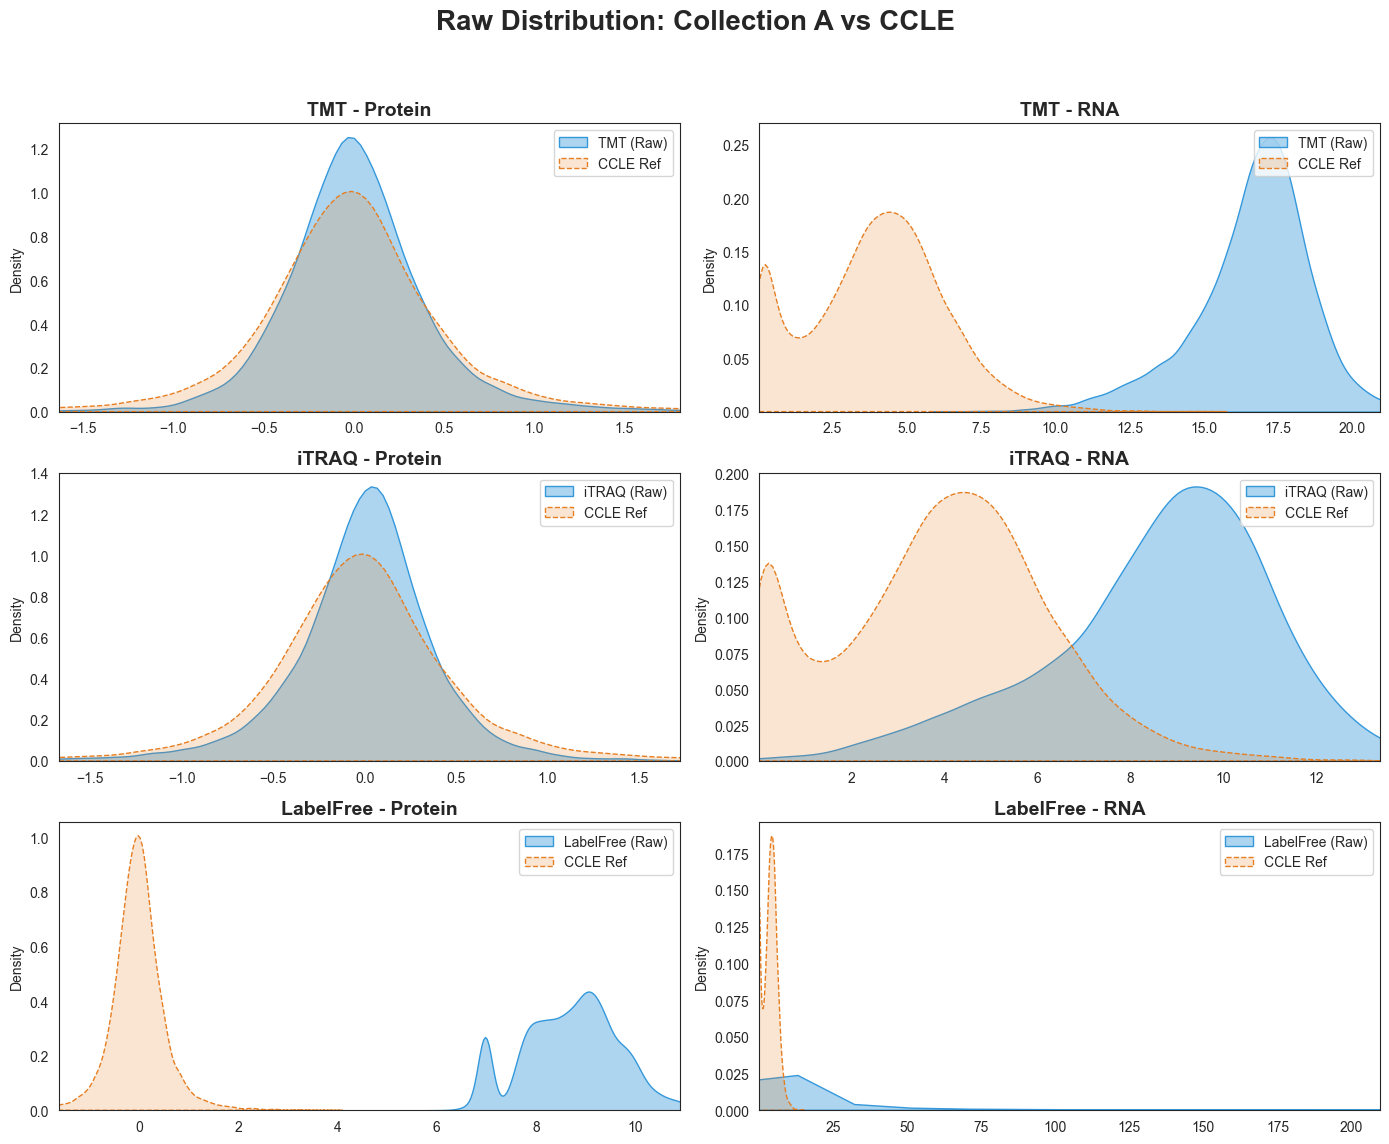

In [11]:
from src.utils_val import get_stats, plot_raw_distributions

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr



# Run Raw Plot
plot_raw_distributions(data_store, ccle_prot, ccle_rna)

### Normalization Strategy

Fit-on-Reference Scaling: All mathematical "rules" (medians, spreads, and means) are calculated using only the CCLE training data to ensure the validation data is viewed through the same "lens" as the model.

Transformation: Uses Log2 for RNA to handle wide dynamic ranges and asinh for proteins to safely compress intensities, including negative ratios.

Peak Alignment: Forces the peaks of both datasets to overlap exactly at zero by subtracting the specific mean difference for every gene and protein.

Robustness: Employs RobustScaler for RNA and Label-Free data to ignore extreme spikes and focus on the main "hill" of the distribution.

#### Dataset-Specific Needs
Different datasets have unique technical signatures that require specialized handling:

RNA (Features): These datasets often have a massive "magnitude gap" (e.g., raw counts vs. TPM). They require Global Median Alignment to move the entire distribution so the model doesn't misinterpret technical scale as a biological signal.

Label-Free Proteomics: This platform is prone to "batch shifts" where the entire dataset is slightly offset. It requires Sample-wise Median Centering to bring different batches into a comparable numerical range.

TMT/iTRAQ Proteomics: Generally more stable and well-aligned with CCLE baselines. These use Standard Scaling to maintain the precise relative expression levels needed for accurate target prediction.



>>> NORMALIZED STATS: TMT - Protein
        Validation_Norm  CCLE_Ref_Norm
Mean       7.904121e-18   1.001700e-18
Median    -1.364543e+00  -1.060796e-02
Std        3.370302e+00   1.000000e+00
Min       -1.147108e+01  -5.531005e+00
Max        1.087752e+01   5.276741e+00
Feature Mean Correlation (Pearson): 0.0292

>>> NORMALIZED STATS: TMT - RNA
        Validation_Norm  CCLE_Ref_Norm
Mean           0.122867       0.122867
Median         0.805644       0.000000
Std            6.312489       2.143948
Min         -328.814605     -11.419076
Max          306.060668     446.730753
Feature Mean Correlation (Pearson): 1.0000

>>> NORMALIZED STATS: iTRAQ - Protein
        Validation_Norm  CCLE_Ref_Norm
Mean       9.709416e-18   1.001700e-18
Median    -2.186271e-03  -1.060796e-02
Std        5.880372e-01   1.000000e+00
Min       -5.561499e+00  -5.531005e+00
Max        4.210231e+00   5.276741e+00
Feature Mean Correlation (Pearson): 0.6094

>>> NORMALIZED STATS: iTRAQ - RNA
        Validation_Norm  

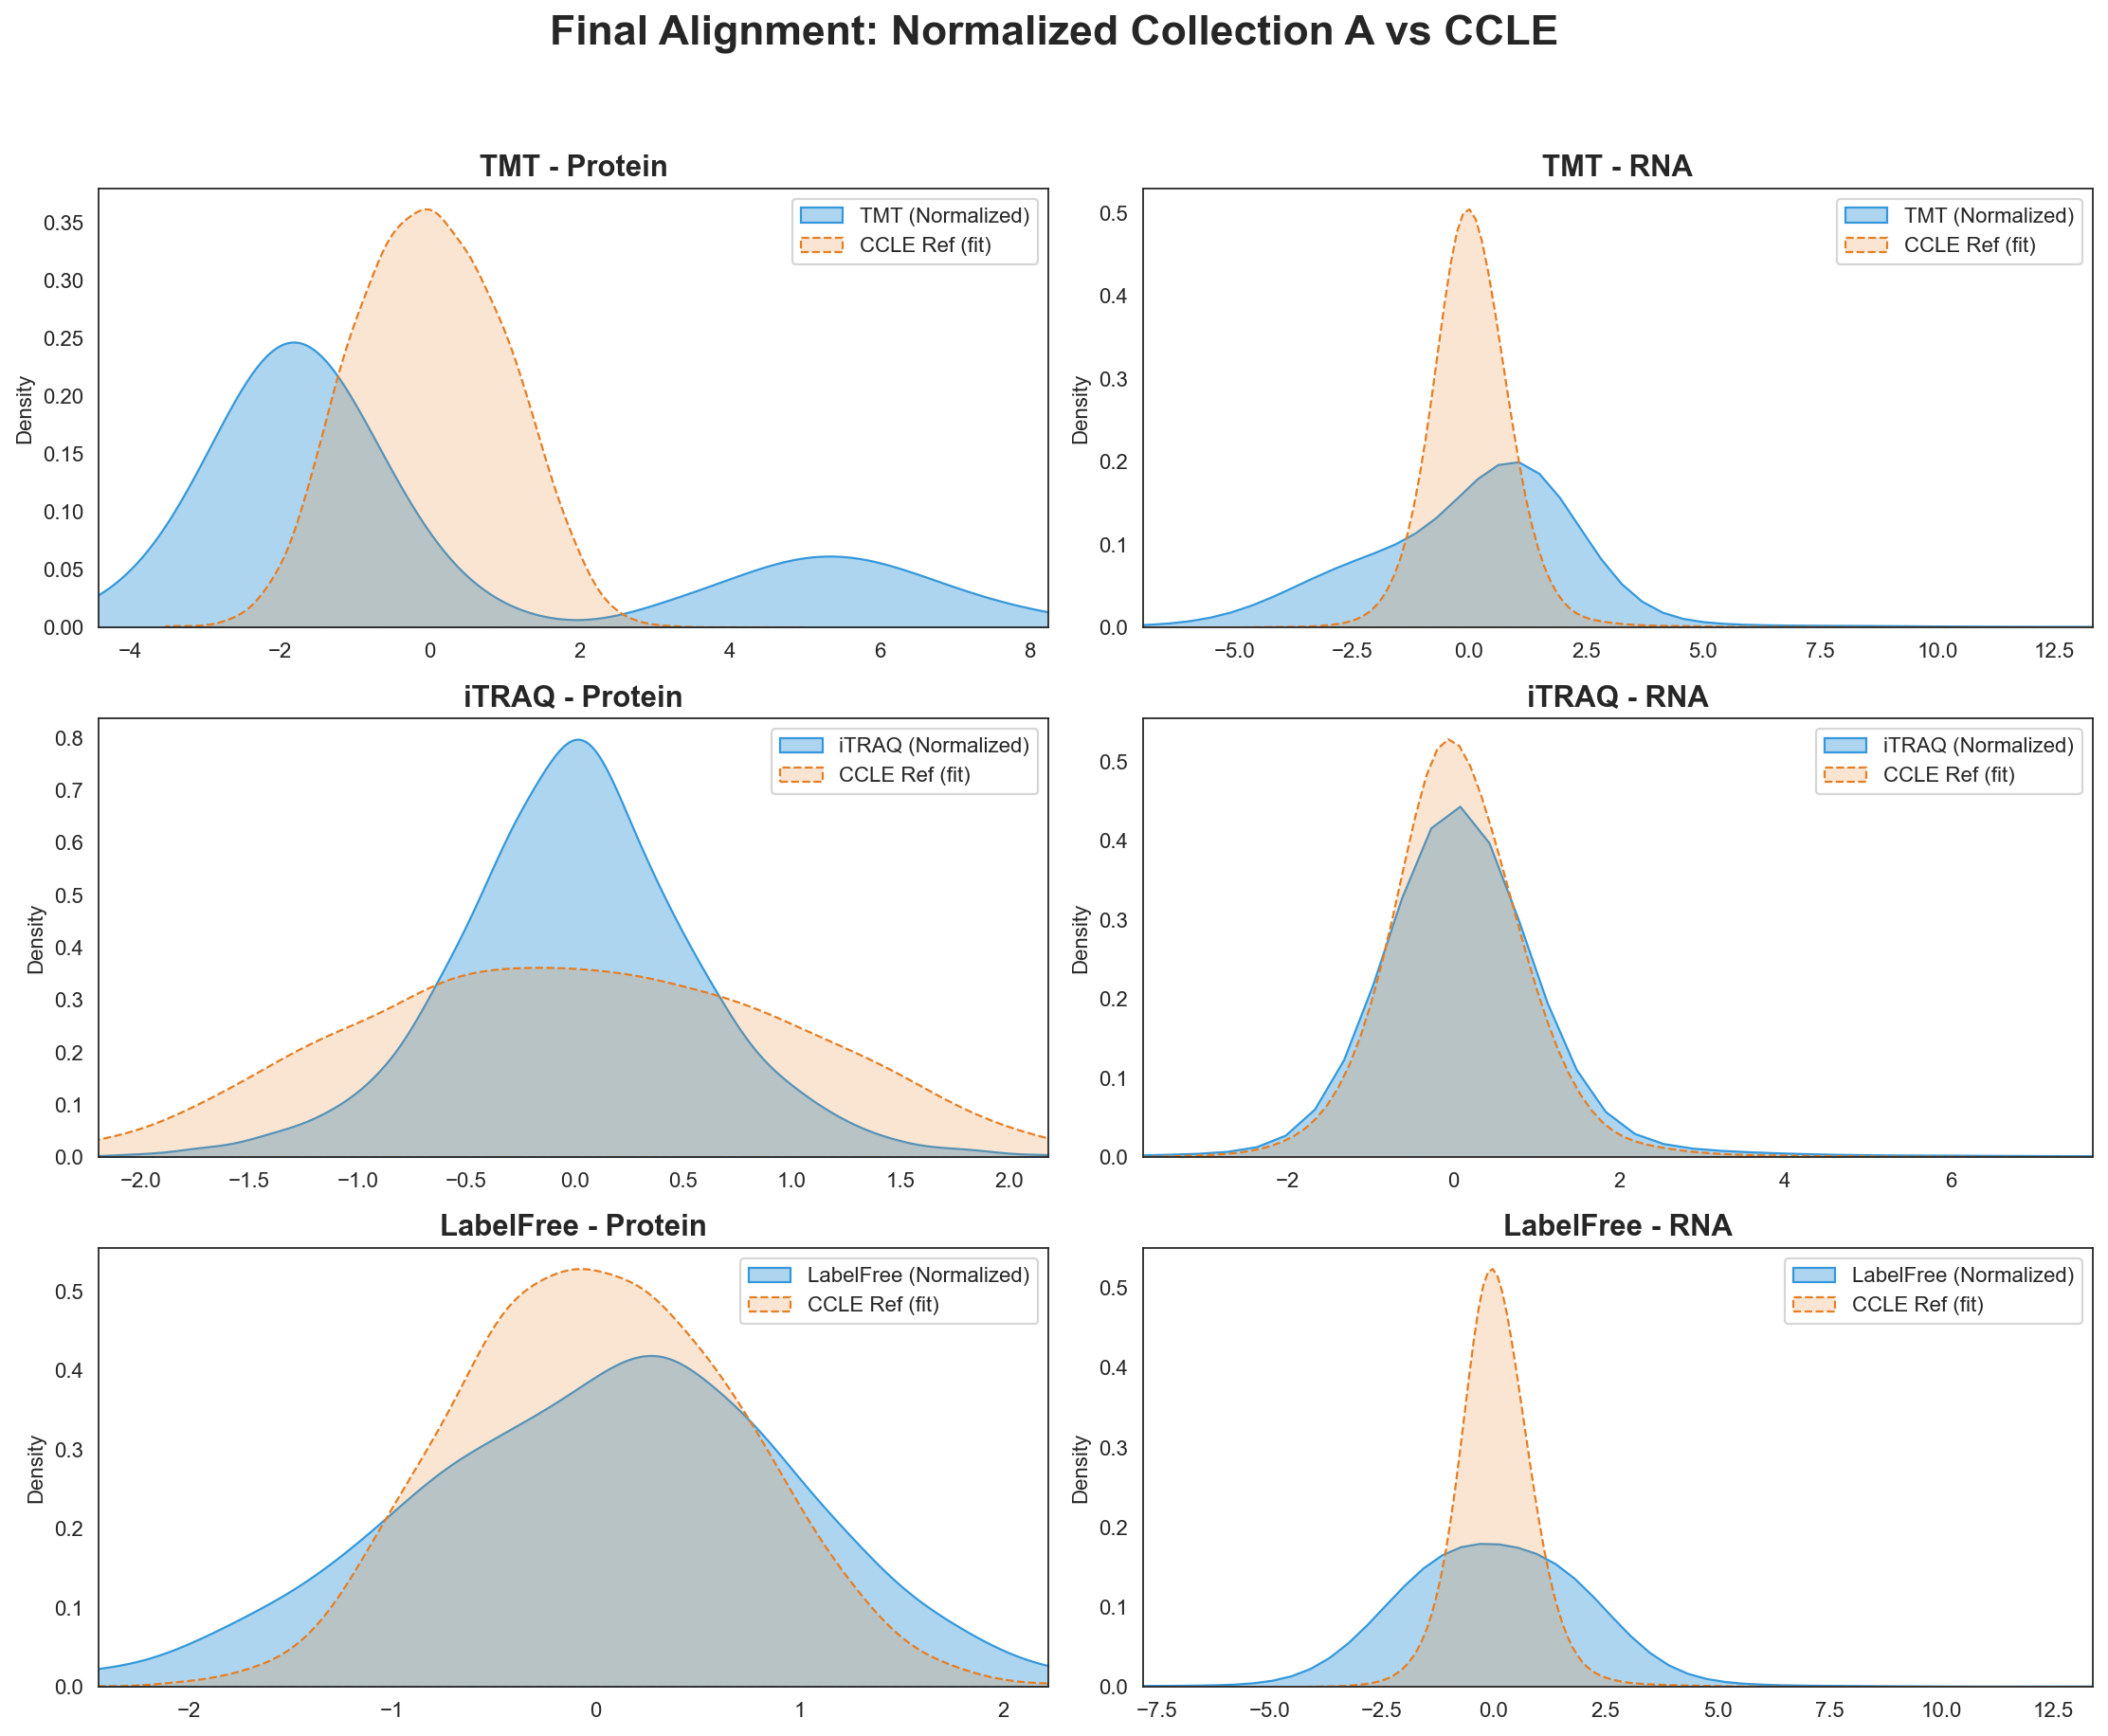

In [12]:
from src.utils_val import (
    _kde_smooth,
    _sample_center_df,
    fit_on_ref_apply,
    get_stats_from_array,
    plot_normalized_distributions,
)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, RobustScaler, QuantileTransformer
from scipy.stats import pearsonr

# ---------------------------
# Make KDE curves render smoothly (avoid "angular" peaks from path simplification)
# ---------------------------
plt.rcParams["path.simplify"] = False
plt.rcParams["path.simplify_threshold"] = 0.0


# ---------------------------
# Plot function (same style as your RAW plot)
# ---------------------------

# Run
plot_normalized_distributions(data_store, ccle_prot, ccle_rna)

### Saving processed validation data

In [13]:
import os
import joblib

# Ensure the validation directory exists
output_dir = "../val_data"
os.makedirs(output_dir, exist_ok=True)

# Configuration from your plotting logic
RNA_TRANSFORM = None
RNA_METHOD = "robust_z"
RNA_CLIP_Q = (0.001, 0.999)

PROT_TRANSFORM = "asinh"
PROT_METHOD_TMT_ITRAQ = "standard_z"
PROT_METHOD_LABELFREE = "robust_z"
LABELFREE_SAMPLE_CENTER = "median"

print("Processing and saving aligned datasets...")

for group in GROUPS:
    for dtype in TYPES:
        df_target = data_store[group][dtype]
        df_ref = ccle_prot if dtype == "Protein" else ccle_rna
        
        if df_target is None:
            continue
            
        # 1. Determine modality-specific parameters (identical to plot logic)
        if dtype == "Protein":
            method = PROT_METHOD_LABELFREE if group == "LabelFree" else PROT_METHOD_TMT_ITRAQ
            sample_center = LABELFREE_SAMPLE_CENTER if group == "LabelFree" else None
            transform = PROT_TRANSFORM
            clip_q = None
            clip_nonneg = False
        else:
            method = RNA_METHOD
            sample_center = None
            transform = RNA_TRANSFORM
            clip_q = RNA_CLIP_Q
            clip_nonneg = (RNA_TRANSFORM == "log2p1")

        # 2. Apply the identical transformation
        # Note: Step 7 in your function ensures the peaks overlap perfectly
        Z_t_df, _, common_feats = fit_on_ref_apply(
            df_target=df_target,
            df_ref=df_ref,
            method=method,
            transform=transform,
            clip_nonneg=clip_nonneg,
            sample_center=sample_center,
            clip_to_ref_quantiles=clip_q
        )

        if Z_t_df is not None:
            # 3. Save the validation features (Z_t_df)
            suffix = "proteomics" if dtype == "Protein" else "transcriptomics"
            save_path = f"{output_dir}/{group}_{suffix}.joblib"
            
            joblib.dump(Z_t_df, save_path)
            print(f"Saved Aligned {group} {dtype} to {save_path} (Shape: {Z_t_df.shape})")
        else:
            print(f"Skipping {group} {dtype}: No overlapping features found.")

print("\nSuccess: All datasets saved identically to the plots.")

Processing and saving aligned datasets...
Saved Aligned TMT Protein to ../val_data/TMT_proteomics.joblib (Shape: (1924, 2153))
Saved Aligned TMT RNA to ../val_data/TMT_transcriptomics.joblib (Shape: (1924, 11822))
Saved Aligned iTRAQ Protein to ../val_data/iTRAQ_proteomics.joblib (Shape: (276, 2153))
Saved Aligned iTRAQ RNA to ../val_data/iTRAQ_transcriptomics.joblib (Shape: (276, 11822))
Saved Aligned LabelFree Protein to ../val_data/LabelFree_proteomics.joblib (Shape: (360, 2153))
Saved Aligned LabelFree RNA to ../val_data/LabelFree_transcriptomics.joblib (Shape: (360, 11822))

Success: All datasets saved identically to the plots.


In [14]:
print("\n=== Protein Lists in Datasets ===")
print(f"CCLE Proteins ({len(ccle_prot.columns)}):")
# Print sorted list for better readability
print(sorted(list(ccle_prot.columns)))

for group in GROUPS:
    df = data_store[group].get('Protein')
    if df is not None:
        print(f"\n{group} Proteins ({len(df.columns)}):")
        print(sorted(list(df.columns)))
    else:
        print(f"\n{group} Protein data not found.")



=== Protein Lists in Datasets ===
CCLE Proteins (2153):
['A2M', 'AARS2', 'AASDHPPT', 'ABCB7', 'ABCD3', 'ABCE1', 'ABCF1', 'ABHD10', 'ABHD11', 'ABHD12', 'ABHD14B', 'ABHD16A', 'ABI1', 'ACAA1', 'ACAA2', 'ACAD10', 'ACAD8', 'ACAD9', 'ACADM', 'ACADS', 'ACADSB', 'ACADVL', 'ACAT1', 'ACAT2', 'ACBD3', 'ACIN1', 'ACLY', 'ACO1', 'ACO2', 'ACOT13', 'ACOT7', 'ACOT9', 'ACOX1', 'ACP1', 'ACP2', 'ACSF2', 'ACSF3', 'ACSL1', 'ACSL3', 'ACSL4', 'ACSL5', 'ACTB', 'ACTL6A', 'ACTN1', 'ACTN4', 'ACTR10', 'ACTR1A', 'ACTR2', 'ACTR3', 'ACY1', 'ADAM10', 'ADAR', 'ADD1', 'ADD3', 'ADH5', 'ADK', 'ADPGK', 'ADRM1', 'ADSL', 'AFG3L2', 'AGK', 'AGL', 'AGO2', 'AGPS', 'AGR2', 'AGRN', 'AHCY', 'AHCYL1', 'AHNAK', 'AHSA1', 'AIDA', 'AIFM1', 'AIMP1', 'AIMP2', 'AIP', 'AK1', 'AK2', 'AK3', 'AK4', 'AKAP1', 'AKAP12', 'AKAP9', 'AKR1A1', 'AKR1B1', 'AKR1C3', 'AKR7A2', 'AKT1', 'AKT2', 'ALAD', 'ALCAM', 'ALDH16A1', 'ALDH18A1', 'ALDH1A1', 'ALDH1B1', 'ALDH2', 'ALDH3A2', 'ALDH4A1', 'ALDH5A1', 'ALDH6A1', 'ALDH7A1', 'ALDH9A1', 'ALDOA', 'ALDOC', 'ALG1', 

In [15]:


output_dir = "../processed_data/feature_lists"
os.makedirs(output_dir, exist_ok=True)
print(f"\n=== Saving Protein and Feature Lists to {output_dir} ===")

for group in GROUPS:
    # Save Protein List
    df_prot = data_store[group].get('Protein')
    if df_prot is not None:
        prot_list = sorted(list(df_prot.columns))
        prot_file = os.path.join(output_dir, f"{group}_proteins.txt")
        with open(prot_file, 'w') as f:
            for item in prot_list:
                f.write(f"{item}\n")
        print(f"Saved {len(prot_list)} proteins to {prot_file}")
    
    # Save RNA (Feature) List
    df_rna = data_store[group].get('RNA')
    if df_rna is not None:
        # RNA dataframe has columns as genes (features)
        rna_list = sorted(list(df_rna.columns))
        rna_file = os.path.join(output_dir, f"{group}_rna_features.txt")
        with open(rna_file, 'w') as f:
            for item in rna_list:
                f.write(f"{item}\n")
        print(f"Saved {len(rna_list)} RNA features to {rna_file}")

print("Done saving lists.")



=== Saving Protein and Feature Lists to ../processed_data/feature_lists ===
Saved 6885 proteins to ../processed_data/feature_lists\TMT_proteins.txt
Saved 15001 RNA features to ../processed_data/feature_lists\TMT_rna_features.txt
Saved 4994 proteins to ../processed_data/feature_lists\iTRAQ_proteins.txt
Saved 14521 RNA features to ../processed_data/feature_lists\iTRAQ_rna_features.txt
Saved 2563 proteins to ../processed_data/feature_lists\LabelFree_proteins.txt
Saved 14947 RNA features to ../processed_data/feature_lists\LabelFree_rna_features.txt
Done saving lists.


# Feature Intersection Analysis
(Merged from feature_intersection.ipynb)

In [16]:


# Ensure output directory exists
output_dir = "../model_results/feature_intersections"
os.makedirs(output_dir, exist_ok=True)


In [17]:
from src.utils_val import load_feature_list

# Paths (Relative to notebooks/ directory)
TRANSCRIPTOMICS_PATH = "../processed_data/transcriptomics_filtered.joblib"
FEAT_LIST_DIR = "../processed_data/feature_lists"

TMT_PATH = os.path.join(FEAT_LIST_DIR, "TMT_rna_features.txt")
ITRAQ_PATH = os.path.join(FEAT_LIST_DIR, "iTRAQ_rna_features.txt")
LF_PATH = os.path.join(FEAT_LIST_DIR, "LabelFree_rna_features.txt")

# Load Transcriptomics Data
print(f"Loading {TRANSCRIPTOMICS_PATH}...")
try:
    data = joblib.load(TRANSCRIPTOMICS_PATH)
    if isinstance(data, pd.DataFrame):
        transcriptomics_genes = set(data.columns)
        print(f"Loaded DataFrame with {len(transcriptomics_genes)} features.")
    elif isinstance(data, (list, set, np.ndarray)):
        transcriptomics_genes = set(data)
        print(f"Loaded list/set with {len(transcriptomics_genes)} features.")
    else:
        print(f"Unknown type: {type(data)}")
        transcriptomics_genes = set()
except Exception as e:
    print(f"Error loading transcriptomics: {e}")
    transcriptomics_genes = set()

# Load Other Feature Lists

tmt_genes = load_feature_list(TMT_PATH)
itraq_genes = load_feature_list(ITRAQ_PATH)
lf_genes = load_feature_list(LF_PATH)

print(f"TMT Genes: {len(tmt_genes)}")
print(f"iTRAQ Genes: {len(itraq_genes)}")
print(f"LabelFree Genes: {len(lf_genes)}")

Loading ../processed_data/transcriptomics_filtered.joblib...
Loaded DataFrame with 22614 features.
TMT Genes: 15001
iTRAQ Genes: 14521
LabelFree Genes: 14947


In [18]:

# Calculate Intersections

# 1. Transcriptomics AND TMT
common_tmt = transcriptomics_genes.intersection(tmt_genes)
print(f"Transcriptomics & TMT: {len(common_tmt)}")

# 2. Transcriptomics AND iTRAQ
common_itraq = transcriptomics_genes.intersection(itraq_genes)
print(f"Transcriptomics & iTRAQ: {len(common_itraq)}")

# 3. Transcriptomics AND LabelFree
common_lf = transcriptomics_genes.intersection(lf_genes)
print(f"Transcriptomics & LabelFree: {len(common_lf)}")

# 4. Common to ALL 4
common_all = transcriptomics_genes.intersection(tmt_genes).intersection(itraq_genes).intersection(lf_genes)
print(f"Common to ALL 4: {len(common_all)}")


Transcriptomics & TMT: 12833
Transcriptomics & iTRAQ: 12380
Transcriptomics & LabelFree: 12673
Common to ALL 4: 11822


In [19]:
from src.utils_val import save_list

uv.configure_runtime_globals(output_dir=output_dir)

save_list(common_tmt, "transcriptomics_and_TMT.txt")
save_list(common_itraq, "transcriptomics_and_iTRAQ.txt")
save_list(common_lf, "transcriptomics_and_LabelFree.txt")
save_list(common_all, "common_all_datasets.txt")

Saved 12833 genes to ../model_results/feature_intersections\transcriptomics_and_TMT.txt
Saved 12380 genes to ../model_results/feature_intersections\transcriptomics_and_iTRAQ.txt
Saved 12673 genes to ../model_results/feature_intersections\transcriptomics_and_LabelFree.txt
Saved 11822 genes to ../model_results/feature_intersections\common_all_datasets.txt
